In [1]:
import badgers
badgers.__version__

'0.0.15'

In [2]:
from badgers.generators.tabular_data.imbalance.causal import CausalImbalanceGenerator

g++ not available, if using conda: `conda install gxx`


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import pandas as pd

In [4]:
def generate_linear_data(graph, n_samples=100, rng=None, coefficients=None):
    """Generate data from a linear structural equation model on a DAG.

    Each edge (u -> v) carries a coefficient w. Every node value is
        v = sum_{u in parents(v)} w_{u,v} * u + noise
    with noise ~ N(0, 1).
    """
    if rng is None:
        rng = np.random.default_rng(42)
    if coefficients is None:
        coefficients = {edge: 1.0 for edge in graph.edges()}

    nodes = list(graph.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    X = np.zeros((n_samples, len(nodes)))
    for node in nx.topological_sort(graph):
        idx = node_to_idx[node]
        parents = list(graph.predecessors(node))
        if not parents:
            X[:, idx] = rng.normal(size=n_samples)
        else:
            X[:, idx] = rng.normal(size=n_samples)
            for parent in parents:
                coef = coefficients.get((parent, node), 1.0)
                X[:, idx] += coef * X[:, node_to_idx[parent]]
    return X, {node: i for i, node in enumerate(nodes)}


def draw_graph(graph, title=None):
    """Draw a DAG with node labels."""
    fig, ax = plt.subplots(1, figsize=(6, 2))
    pos = nx.spring_layout(graph, seed=42)
    nx.draw(graph, pos, ax=ax, node_color="lightblue", node_size=800, arrowsize=15)
    nx.draw_networkx_labels(graph, pos, ax=ax)
    if title:
        ax.set_title(title, fontsize=12)
    ax.axis("off")
    return fig


def plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name="X", y_name="Y"):
    """Original | Transformed scatter of two dimensions.

    The transformed panel is coloured by the generator's labels (which rows
    received the defect). Rows with NaN values are drawn as black 'x' markers.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    sns.scatterplot(x=X[:, x_idx], y=X[:, y_idx], color="C0", ax=axes[0])
    sns.scatterplot(x=Xt[:, x_idx], y=Xt[:, y_idx], color="C1", ax=axes[1])
    axes[0].set_title("Original")
    axes[1].set_title("Transformed")
    axes[0].set_xlabel(x_name)
    axes[1].set_xlabel(x_name)
    axes[0].set_ylabel(y_name)
    axes[1].set_ylabel(y_name)
    plt.tight_layout()
    return fig

## 1. Building the causal graph

Unlike the classic Badgers generators, the causal generators take a **causal graph** (a directed acyclic graph, or DAG) as input. The graph plays two roles:

1. **It defines the data.** We generate the data *from* the graph using a linear structural equation model, so the graph genuinely explains how the columns are related.
2. **It drives the defect.** When a node is perturbed, the effect **propagates to its descendants** along the directed edges and nowhere else.

For these tutorials we use a simple **chain** `X → Y → Z`:

- **X** is a root (exogenous) node.
- **Y** depends on X.
- **Z** depends on Y.

We represent the graph with `networkx.DiGraph` and provide an explicit `column_mapping` that tells the generator which column of the data each node lives in.


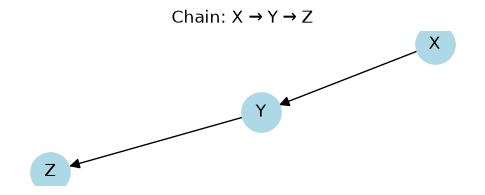

In [5]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

draw_graph(chain, title="Chain: X → Y → Z")
plt.show()


## 2. Generating data from the DAG

We draw 100 samples from the chain. Each node is a weighted sum of its parents plus Gaussian noise; the edge weights set the strength of each causal effect.


In [6]:
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={("X", "Y"): 2.0, ("Y", "Z"): 0.5},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")


X shape: (100, 3)
column_mapping: {'X': 0, 'Y': 1, 'Z': 2}


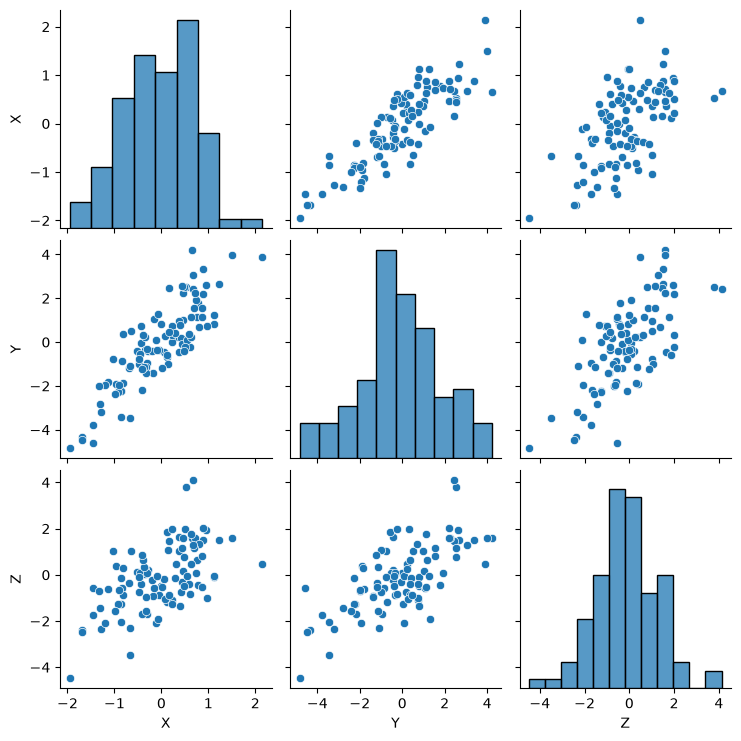

In [7]:
sns.pairplot(pd.DataFrame(X, columns=column_mapping.keys()))

## 3. Fitting the data generation process (DGP)

Causal generators run in **two phases**:

1. **`fit(X, graph, column_mapping)`** — fits a Bayesian data generation process (a `PyMCDGP`, built on PyMC) to the *original* data. It learns, for every node, the linear coefficients from its parents and the residual noise.
2. **`generate(...)`** — perturbs the chosen node(s), then **propagates** the effect to descendants using the fitted structural equations.

Fitting needs the optional `causal` extra (`pip install "badgers[causal]"`). We use a modest number of MCMC samples for speed; raise `n_samples_mcmc` for a more precise fit, or lower it for a faster notebook.


In [8]:
gen = CausalImbalanceGenerator(random_generator=np.random.default_rng(0))
gen.fit(X.copy(), chain, column_mapping, n_samples_mcmc=500)
print("DGP fitted on", X.shape[0], "rows")


Initializing NUTS using jitter+adapt_diag...
C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\pytensor\tensor\rewriting\elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Sequential sampling (1 chains in 1 job)
NUTS: [mu_X, sigma_X, X_X, sigma_obs_X, beta_Y, sigma_Y, X_Y, sigma_obs_Y, beta_Z, sigma_Z, X_Z, sigma_obs_Z]
Sampling 1 chain for 250 tune and 500 draw iterations (250 + 500 draws total) took 8 seconds.
Only one chain was sampled, this makes it impossible to run some convergence checks


DGP fitted on 100 rows


## 4. Generate causally-propagated imbalance

    "The `CausalImbalanceGenerator` **truncates the dataset**: it keeps only the rows whose perturbation node falls inside `quantile_range`. Since the kept rows' parents are unchanged, the propagated delta is exactly 0 — the descendants are untouched. The result is a *pure subset*: a dataset that is *imbalanced* — concentrated in one part of the perturbation node's range — while remaining structurally consistent by construction.\n"


In [9]:
Xt, yt = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    quantile_range=(0.5, 1.0),
)
print(f"kept {Xt.shape[0]} of {X.shape[0]} rows")


kept 50 of 100 rows


In [10]:
Xt[:5]

array([[ 0.30471708,  0.23127161,  0.45321035],
       [ 0.7504512 ,  1.14463842,  0.66290412],
       [ 0.94056472,  2.618645  ,  1.95326129],
       [-0.01680116,  0.80670582, -0.47479946],
       [ 0.87939797,  2.19321959,  2.01251234]])

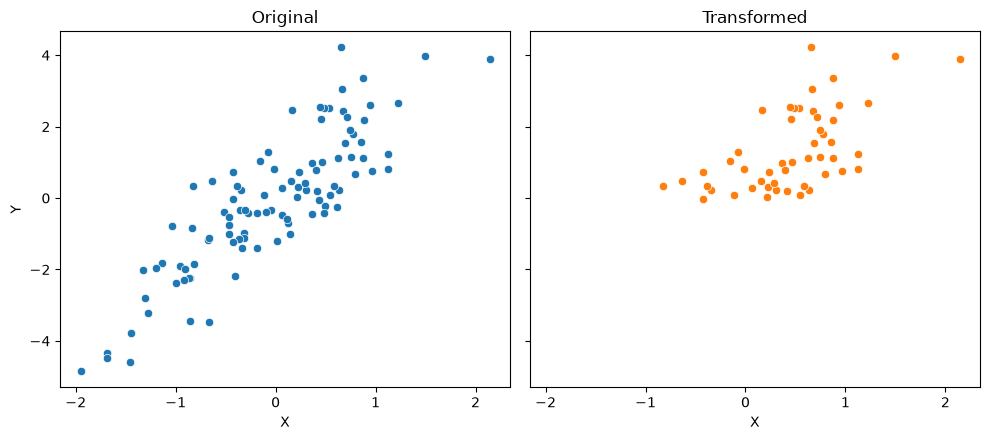

In [11]:
_ = plot_2panel(X, Xt, yt, x_name='X', y_name='Y')

### The other half of the range

`quantile_range=(0.5, 1.0)` keeps the *upper* half of Y. Keeping the *lower* half instead gives the complementary imbalance:


kept 50 of 100 rows


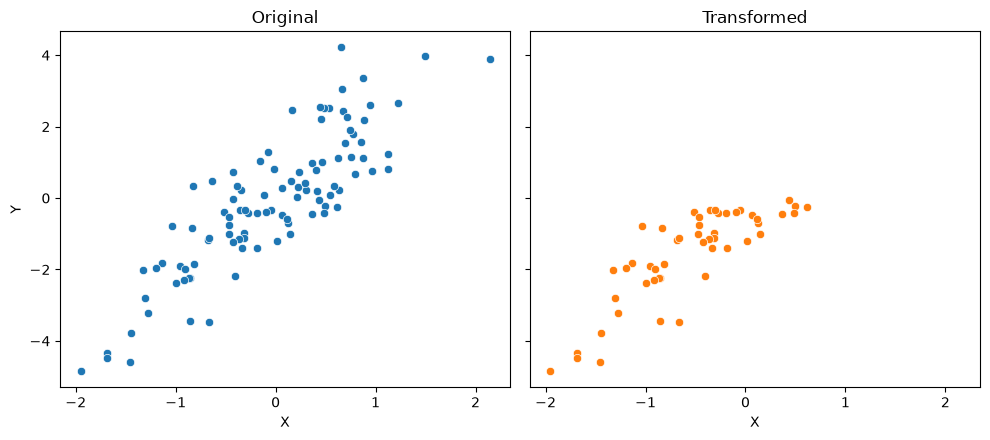

In [14]:
Xt_lo, yt_lo = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    quantile_range=(0.0, 0.5),
)
print(f"kept {Xt_lo.shape[0]} of {X.shape[0]} rows")
_ = plot_2panel(X, Xt_lo, yt_lo, x_name='X', y_name='Y')


### Effect on the descendant (Y → Z)

The truncation removes part of the Y range; the surviving Z values are untouched (delta 0 from unchanged parents) — the Y → Z cloud is simply thinner: the same relationship, on fewer rows.


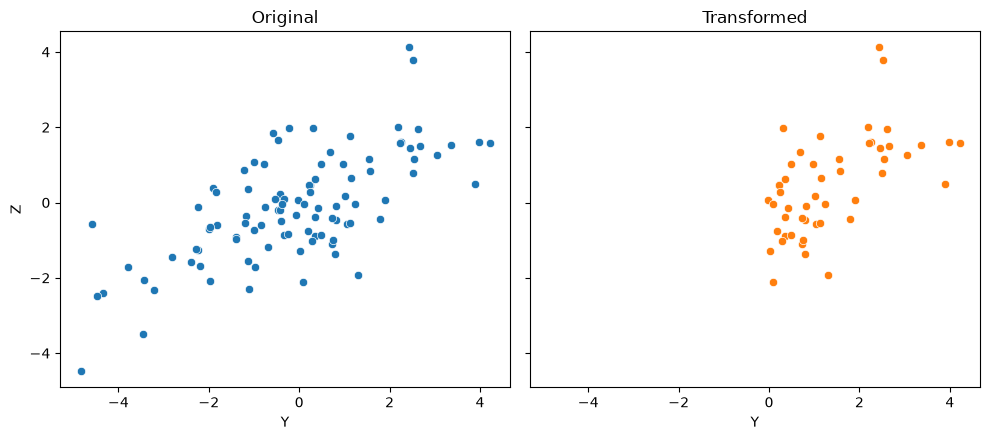

In [15]:
_ = plot_2panel(X, Xt, yt, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

## Summary

1. Imbalance here = keeping a quantile slice of the perturbation node.
2. Descendants are untouched: the delta from unchanged parents is 0, so the result is a pure subset.
3. `quantile_range` controls which part of the range survives.
